Nama: Kirana Aripuspa Wardani

NIM: 2404010010
#Diagnosis Tumor Payudara (Jinak atau Ganas) dengan Machine Learning

###**1. Permasalahan yang Dihadapi**

Kanker payudara merupakan salah satu masalah kesehatan yang membutuhkan deteksi dini dan diagnosis yang akurat. Berdasarkan data GLOBOCAN 2022 dari WHO/IARC, terdapat 66.271 kasus baru kanker payudara di Indonesia, menjadikannya kanker dengan jumlah kasus tertinggi di Indonesia.


Pemeriksaan tumor melalui biopsi aspirasi jarum halus (Fine Needle Aspiration/FNA) dapat membantu menentukan apakah tumor bersifat jinak (benign) atau ganas (malignant). Untuk mendukung proses klasifikasi, Machine Learning digunakan untuk memprediksi jenis tumor berdasarkan karakteristik inti sel.


Dalam proyek ini, perhatian khusus diberikan pada recall kelas ganas dan false negative, yaitu kondisi ketika tumor ganas salah diprediksi sebagai jinak.

###**2. Metode Klasifikasi**

Pada proyek ini, lima metode klasifikasi dibandingkan, yaitu Decision Tree yang membuat aturan keputusan berbentuk pohon, Random Forest yang menggabungkan banyak pohon keputusan, K-Nearest Neighbors (KNN) yang menentukan kelas berdasarkan tetangga terdekat, Naive Bayes yang menggunakan perhitungan probabilitas, serta Support Vector Machine (SVM) yang mencari batas terbaik untuk memisahkan kelas. Kinerja setiap metode dievaluasi menggunakan metrik accuracy, precision, recall, F1-score, dan ROC-AUC, dengan tumor ganas sebagai kelas positif. Nilai recall diperhatikan secara khusus untuk mengetahui kemampuan model dalam mengenali tumor ganas.

###**3. Dataset**

Dataset yang digunakan adalah Breast Cancer Wisconsin (Diagnostic) yang berasal dari UCI Machine Learning Repository dan tersedia melalui library Scikit-learn. Dataset ini terdiri dari 569 sampel dengan 30 fitur numerik untuk mengklasifikasikan tumor payudara menjadi jinak (benign) atau ganas (malignant). Fitur tersebut menggambarkan karakteristik inti sel dari citra FNA, seperti radius, tekstur, perimeter, area, dan bentuk sel, yang diukur dalam tiga jenis nilai, yaitu mean, standard error, dan worst.

###**4. Tahapan Penerapan**

Proyek ini menggunakan kerangka kerja CRISP-DM yang terdiri dari enam tahap. Business Understanding digunakan untuk merumuskan permasalahan klasifikasi tumor, Data Understanding untuk memahami karakteristik dataset, dan Data Preparation untuk menyiapkan data sebelum pemodelan. Selanjutnya, tahap Modelling dilakukan dengan membandingkan lima metode klasifikasi, kemudian Evaluation digunakan untuk menilai performa model melalui metrik evaluasi, confusion matrix, dan kurva ROC. Terakhir, tahap Deployment menerapkan model terbaik ke dalam fungsi prediksi sederhana.

##1. Pemahaman Data
Kode ini digunakan untuk memahami karakteristik dataset tumor payudara, mulai dari memuat data, menentukan label klasifikasi jinak dan ganas, memeriksa nilai kosong dan data duplikat, melihat distribusi kelas, membandingkan fitur tumor melalui histogram, hingga menganalisis korelasi antara fitur dan tumor ganas.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

RANDOM_STATE = 42

In [ ]:
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()

# Di scikit-learn: target 0 = ganas (malignant), 1 = jinak (benign).
# Dibuat ulang agar 1 = GANAS, supaya recall/precision otomatis mengukur kelas ganas.
df["ganas"] = (df["target"] == 0).astype(int)
df = df.drop(columns="target")

print("Ukuran data:", df.shape)
df.head()

Ukuran data: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,ganas
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


Jumlah nilai kosong: 0
Jumlah baris duplikat: 0

ganas
Jinak    357
Ganas    212
Name: count, dtype: int64
ganas
Jinak    62.7 %
Ganas    37.3 %
Name: count, dtype: object


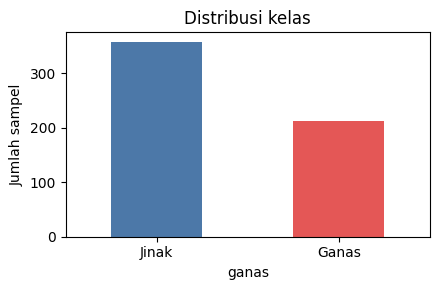

In [ ]:
print("Jumlah nilai kosong:", int(df.isna().sum().sum()))
print("Jumlah baris duplikat:", int(df.duplicated().sum()))
print()
dist = df["ganas"].map({0: "Jinak", 1: "Ganas"}).value_counts()
print(dist)
print((dist / dist.sum() * 100).round(1).astype(str) + " %")

dist.plot(kind="bar", color=["#4C78A8", "#E45756"], figsize=(4.5, 3))
plt.title("Distribusi kelas"); plt.ylabel("Jumlah sampel"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

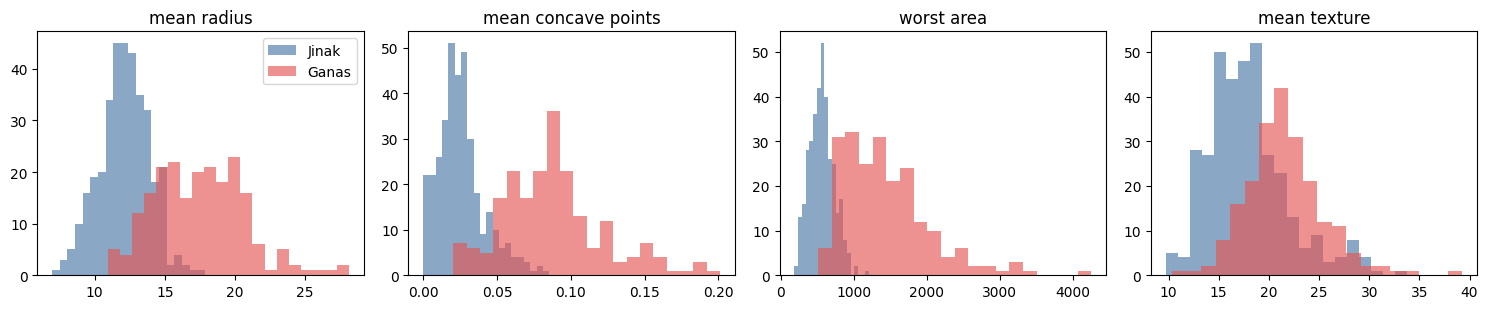

In [ ]:
# Perbandingan beberapa fitur antara tumor jinak dan ganas
fitur_contoh = ["mean radius", "mean concave points", "worst area", "mean texture"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, f in zip(axes, fitur_contoh):
    ax.hist(df.loc[df.ganas == 0, f], bins=20, alpha=0.65, label="Jinak", color="#4C78A8")
    ax.hist(df.loc[df.ganas == 1, f], bins=20, alpha=0.65, label="Ganas", color="#E45756")
    ax.set_title(f)
axes[0].legend()
plt.tight_layout(); plt.show()

In [ ]:
korelasi = df.corr()["ganas"].drop("ganas").sort_values(ascending=False)
print("10 fitur paling berkorelasi dengan tumor ganas:")
print(korelasi.head(10).round(3))

10 fitur paling berkorelasi dengan tumor ganas:
worst concave points    0.794
worst perimeter         0.783
mean concave points     0.777
worst radius            0.776
mean perimeter          0.743
worst area              0.734
mean radius             0.730
mean area               0.709
mean concavity          0.696
worst concavity         0.660
Name: ganas, dtype: float64


##2. Persiapan Data
Kode ini digunakan untuk memisahkan fitur (X) dan label target (y), kemudian membagi dataset menjadi 80% data latih (training) dan 20% data uji (testing). Parameter stratify=y digunakan untuk menjaga proporsi kelas tumor jinak dan ganas tetap seimbang pada kedua bagian data.

In [ ]:
X = df.drop(columns="ganas")
y = df["ganas"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print("Proporsi ganas di data latih:", round(y_train.mean(), 3), "| di data uji:", round(y_test.mean(), 3))

Data latih: (455, 30) | Data uji: (114, 30)
Proporsi ganas di data latih: 0.374 | di data uji: 0.368


##3. Pemodelan
Kode ini digunakan untuk membangun dan membandingkan lima model klasifikasi, yaitu Decision Tree, Random Forest, K-Nearest Neighbors (KNN), Naive Bayes, dan Support Vector Machine (SVM). Evaluasi dilakukan menggunakan 5-fold cross-validation dengan metrik accuracy, precision, recall, F1-score, dan ROC-AUC. Selain itu, kode menampilkan grafik perbandingan performa model serta menganalisis pengaruh kedalaman pohon terhadap akurasi Decision Tree.

In [ ]:
models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Naive Bayes": GaussianNB(),
    "SVM": make_pipeline(StandardScaler(), SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

baris = []
for nama, m in models.items():
    hasil = cross_validate(m, X_train, y_train, cv=cv, scoring=scoring)
    baris.append({"Model": nama, **{k: hasil["test_" + k].mean() for k in scoring}})

hasil_cv = pd.DataFrame(baris).set_index("Model").round(4).sort_values("f1", ascending=False)
hasil_cv

,accuracy,precision,recall,f1,roc_auc
Model,,,,,
SVM,0.9714,0.9769,0.9471,0.9610,0.9949
KNN,0.9648,0.9875,0.9176,0.9510,0.9871
Random Forest,0.9626,0.9638,0.9353,0.9489,0.9889
Naive Bayes,0.9407,0.9402,0.9000,0.9185,0.9878
Decision Tree,0.9209,0.9198,0.8647,0.8897,0.9023


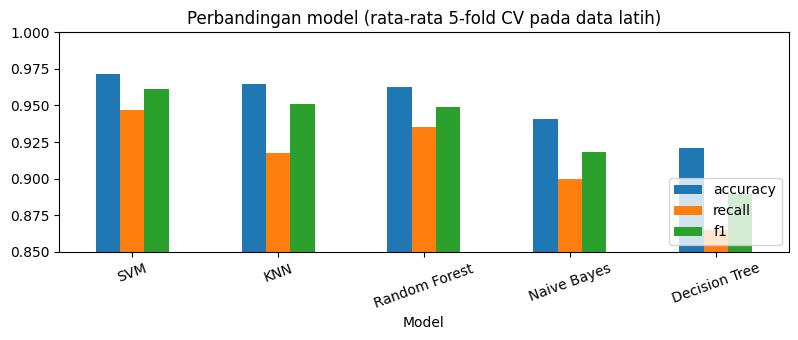

In [ ]:
hasil_cv[["accuracy", "recall", "f1"]].plot(kind="bar", figsize=(8, 3.5))
plt.title("Perbandingan model (rata-rata 5-fold CV pada data latih)")
plt.ylim(0.85, 1.0); plt.xticks(rotation=20); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

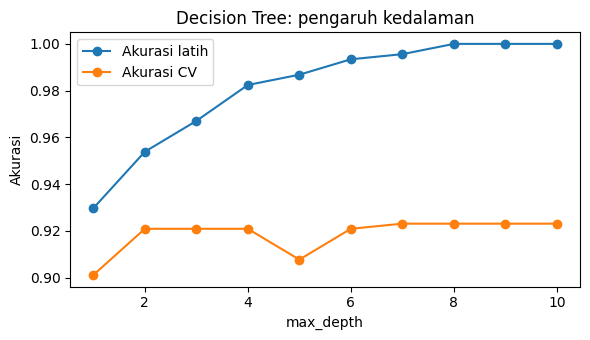

In [ ]:
# Pengaruh kedalaman pohon pada Decision Tree (underfitting vs overfitting)
kedalaman = range(1, 11)
skor_latih, skor_cv = [], []
for d in kedalaman:
    t = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    skor_latih.append(t.fit(X_train, y_train).score(X_train, y_train))
    skor_cv.append(cross_validate(t, X_train, y_train, cv=cv, scoring="accuracy")["test_score"].mean())

plt.figure(figsize=(6, 3.5))
plt.plot(kedalaman, skor_latih, marker="o", label="Akurasi latih")
plt.plot(kedalaman, skor_cv, marker="o", label="Akurasi CV")
plt.xlabel("max_depth"); plt.ylabel("Akurasi"); plt.title("Decision Tree: pengaruh kedalaman")
plt.legend(); plt.tight_layout(); plt.show()

##4. Evaluasi
Kode ini digunakan untuk mengevaluasi performa lima model klasifikasi pada data uji menggunakan metrik accuracy, precision, recall, F1-score, dan ROC-AUC. Kode juga menampilkan confusion matrix dan kurva ROC untuk membandingkan hasil prediksi setiap model, menentukan model terbaik berdasarkan nilai F1 cross-validation pada data latih, menampilkan laporan klasifikasi, serta melihat fitur yang berpengaruh melalui visualisasi Decision Tree dan feature importance Random Forest.

In [ ]:
hasil_uji = []
prediksi = {}
proba = {}
for nama, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    prob = m.predict_proba(X_test)[:, 1]
    prediksi[nama], proba[nama] = pred, prob
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    hasil_uji.append({
        "Model": nama,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "False Negative": fn,
        "False Positive": fp,
    })

tabel_uji = pd.DataFrame(hasil_uji).set_index("Model").round(4).sort_values("F1", ascending=False)
tabel_uji

,Accuracy,Precision,Recall,F1,ROC-AUC,False Negative,False Positive
Model,,,,,,,
SVM,0.9737,1.0000,0.9286,0.9630,0.9947,3,0
Random Forest,0.9649,1.0000,0.9048,0.9500,0.9942,4,0
KNN,0.9561,0.9744,0.9048,0.9383,0.9823,4,1
Naive Bayes,0.9386,1.0000,0.8333,0.9091,0.9934,7,0
Decision Tree,0.9123,0.9444,0.8095,0.8718,0.8770,8,2


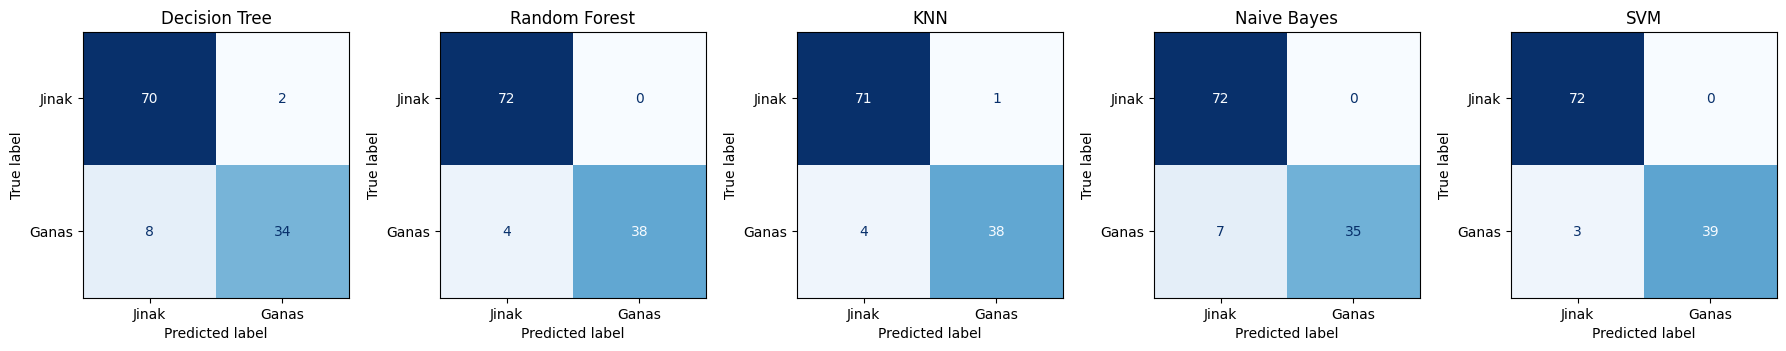

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.4))
for ax, (nama, pred) in zip(axes, prediksi.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["Jinak", "Ganas"], ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nama)
plt.tight_layout(); plt.show()

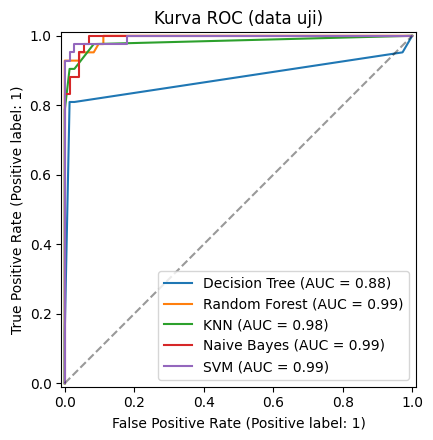

In [ ]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for nama, prob in proba.items():
    RocCurveDisplay.from_predictions(y_test, prob, name=nama, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax.set_title("Kurva ROC (data uji)")
plt.tight_layout(); plt.show()

In [ ]:
# Model dipilih berdasarkan F1 cross-validation pada DATA LATIH (bukan data uji), agar data uji tetap adil
model_terbaik = hasil_cv.index[0]
print("Model terpilih (F1 tertinggi pada cross-validation data latih):", model_terbaik)
print()
print(classification_report(y_test, prediksi[model_terbaik], target_names=["Jinak", "Ganas"]))

Model terpilih (F1 tertinggi pada cross-validation data latih): SVM

              precision    recall  f1-score   support

       Jinak       0.96      1.00      0.98        72
       Ganas       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



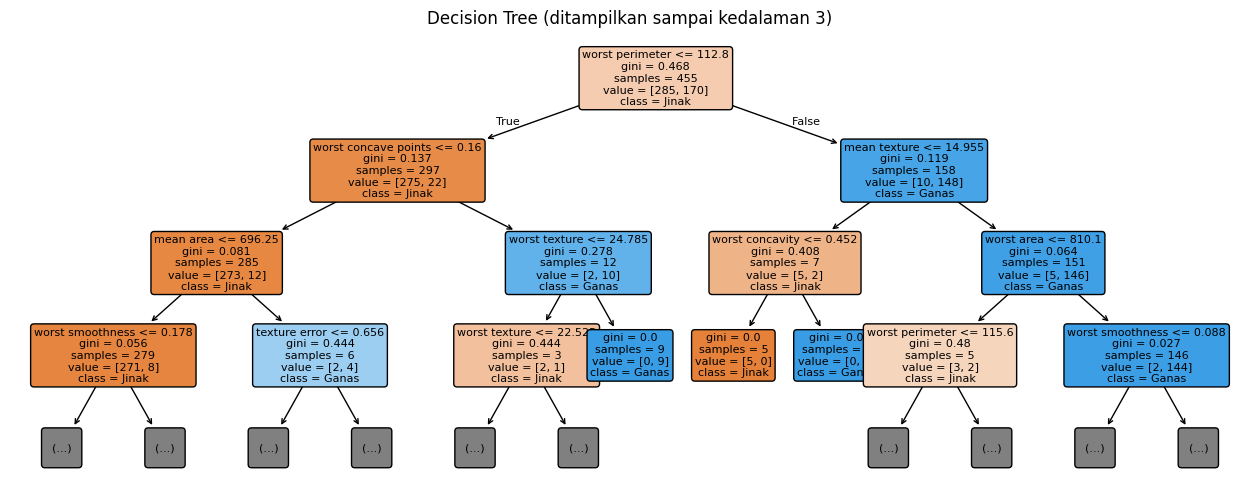

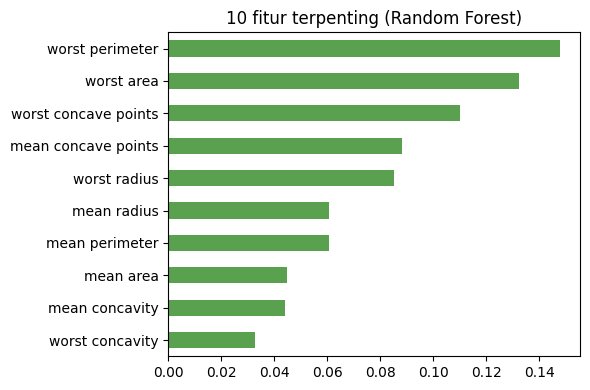

In [ ]:
# Interpretasi: pohon keputusan (kedalaman 3 agar mudah dibaca) dan fitur terpenting Random Forest
plt.figure(figsize=(16, 6))
plot_tree(models["Decision Tree"], feature_names=list(X.columns), class_names=["Jinak", "Ganas"],
          filled=True, rounded=True, fontsize=8, max_depth=3)
plt.title("Decision Tree (ditampilkan sampai kedalaman 3)")
plt.show()

pentingnya = pd.Series(models["Random Forest"].feature_importances_, index=X.columns).sort_values(ascending=False)
pentingnya.head(10).sort_values().plot(kind="barh", figsize=(6, 4), color="#59A14F")
plt.title("10 fitur terpenting (Random Forest)")
plt.tight_layout(); plt.show()

##5. Penerapan Model
Kode ini digunakan untuk menerapkan model klasifikasi terbaik yang telah dipilih, kemudian membuat fungsi prediksi tumor berdasarkan data fitur yang diberikan. Model menghasilkan prediksi tumor jinak atau ganas beserta estimasi probabilitas tumor ganas, lalu menguji fungsi tersebut pada tiga sampel data uji dan membandingkan hasil prediksi dengan label sebenarnya.

In [ ]:
final_model = models[model_terbaik]

def prediksi_tumor(baris_fitur):
    """baris_fitur: DataFrame 1 baris dengan 30 kolom fitur yang sama seperti X."""
    p = final_model.predict_proba(baris_fitur)[0, 1]
    return ("GANAS" if p >= 0.5 else "JINAK"), p

for i in [0, 1, 2]:
    contoh = X_test.iloc[[i]]
    label, p = prediksi_tumor(contoh)
    aktual = "GANAS" if y_test.iloc[i] == 1 else "JINAK"
    print(f"Sampel uji #{i}: prediksi {label} (peluang ganas {p:.2%}) | diagnosis sebenarnya: {aktual}")

Sampel uji #0: prediksi JINAK (peluang ganas 0.16%) | diagnosis sebenarnya: JINAK
Sampel uji #1: prediksi GANAS (peluang ganas 100.00%) | diagnosis sebenarnya: GANAS
Sampel uji #2: prediksi JINAK (peluang ganas 6.16%) | diagnosis sebenarnya: JINAK


##6. Hasil dan Pembahasan
Kode ini digunakan untuk merangkum hasil evaluasi model klasifikasi, menampilkan performa model terbaik berdasarkan F1-score cross-validation pada data latih, serta membandingkan nilai accuracy, precision, recall, F1-score, dan ROC-AUC pada data uji. Kode juga menampilkan jumlah kasus tumor ganas yang salah diprediksi sebagai jinak (false negative) dan fitur yang paling penting menurut model Random Forest.

In [ ]:
terbaik = tabel_uji.loc[model_terbaik]
print("RINGKASAN HASIL (dihitung otomatis dari model di atas)")
print("-" * 60)
print(f"Data: {len(df)} sampel, {X.shape[1]} fitur | latih {len(X_train)} / uji {len(X_test)}")
print(f"Model terpilih (CV data latih)  : {model_terbaik}")
print(f"Accuracy / Precision / Recall  : {terbaik['Accuracy']:.2%} / {terbaik['Precision']:.2%} / {terbaik['Recall']:.2%}")
print(f"F1 / ROC-AUC                   : {terbaik['F1']:.2%} / {terbaik['ROC-AUC']:.3f}")
print(f"False negative (ganas lolos)   : {int(terbaik['False Negative'])} dari {int(y_test.sum())} kasus ganas pada data uji")
print(f"Fitur terpenting Random Forest : {pentingnya.index[0]}")
print()
print("Peringkat semua model (F1, data uji):")
print(tabel_uji[["Accuracy", "Recall", "F1"]])

RINGKASAN HASIL (dihitung otomatis dari model di atas)
------------------------------------------------------------
Data: 569 sampel, 30 fitur | latih 455 / uji 114
Model terpilih (CV data latih)  : SVM
Accuracy / Precision / Recall  : 97.37% / 100.00% / 92.86%
F1 / ROC-AUC                   : 96.30% / 0.995
False negative (ganas lolos)   : 3 dari 42 kasus ganas pada data uji
Fitur terpenting Random Forest : worst perimeter

Peringkat semua model (F1, data uji):
               Accuracy  Recall      F1
Model                                  
SVM              0.9737  0.9286  0.9630
Random Forest    0.9649  0.9048  0.9500
KNN              0.9561  0.9048  0.9383
Naive Bayes      0.9386  0.8333  0.9091
Decision Tree    0.9123  0.8095  0.8718


##Pembahasan

1. Perbandingan Model

Kelima model klasifikasi menunjukkan performa yang baik pada dataset ini. Pemilihan model tidak hanya berdasarkan accuracy, tetapi juga recall dan jumlah false negative, yaitu kasus tumor ganas yang salah diprediksi sebagai jinak.

2. Pentingnya Recall dan False Negative

Dalam klasifikasi tumor, kesalahan memprediksi tumor ganas sebagai jinak perlu mendapat perhatian karena berisiko membuat kasus tidak terdeteksi. Oleh karena itu, model dengan recall tinggi dan false negative rendah lebih diutamakan.

3. Interpretasi Model dan Fitur

Decision Tree lebih mudah dipahami karena menghasilkan aturan keputusan yang dapat dibaca, sedangkan Random Forest dan SVM memiliki proses prediksi yang lebih kompleks. Fitur terkait ukuran dan bentuk inti sel, seperti radius, perimeter, dan concave points, dapat membantu membedakan tumor jinak dan ganas.

4. Pengaruh Kedalaman Decision Tree

Semakin dalam pohon keputusan, akurasi pada data latih cenderung meningkat. Namun, jika terlalu dalam, model berisiko mengalami overfitting, yaitu terlalu menyesuaikan diri dengan data latih sehingga kemampuan pada data baru dapat menurun.

##Manfaat

1. Alat Bantu Klasifikasi: Machine Learning dapat membantu mengklasifikasikan tumor jinak dan ganas sebagai pendukung pemeriksaan tenaga medis, bukan sebagai pengganti diagnosis dokter.

2. Efisiensi Pemeriksaan: Model dapat memproses data dengan cepat dan menerapkan pola klasifikasi yang konsisten pada setiap sampel.

3. Mengetahui Fitur Penting: Analisis model membantu mengetahui karakteristik sel yang berperan dalam membedakan tumor jinak dan ganas.

4. Bahan Penelitian: Hasil klasifikasi dapat menjadi bahan pembelajaran dan penelitian untuk pengembangan sistem pendukung diagnosis tumor payudara.

##Kesimpulan

Berdasarkan hasil pengujian pada dataset Breast Cancer Wisconsin (Diagnostic), kelima metode Machine Learning mampu mengklasifikasikan tumor jinak dan ganas dengan performa yang baik. Pemilihan model terbaik mempertimbangkan nilai F1-score, recall kelas ganas, dan jumlah false negative. Hasil ini menunjukkan bahwa Machine Learning berpotensi digunakan sebagai alat bantu klasifikasi tumor. Namun, model masih perlu diuji menggunakan data yang lebih beragam dan divalidasi lebih lanjut sebelum dapat dipertimbangkan untuk penggunaan klinis.

###Referensi

International Agency for Research on Cancer (IARC). (2024). *Global Cancer Observatory: Indonesia Fact Sheet, GLOBOCAN 2022*. World Health Organization.


Scikit-learn Developers. (n.d.). *Breast cancer Wisconsin (diagnostic) dataset*. Scikit-learn Documentation. https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html


Munir, A. S., Saputra, A. B., Aziz, A., & Barata, M. A. (2024). Perbandingan Akurasi Algoritma Naive Bayes dan Algoritma Decision Tree dalam Pengklasifikasian Penyakit Kanker Payudara. *Jurnal Ilmiah Informatika Global*, 15(1), 23–29.